# Module 2 — Prétraitement XAU/USD (daily)

Première étape du pipeline (prétraitement → calibration GBM → Monte Carlo →
VaR/ES → backtesting Kupiec) : chargement, validation, gestion du trou de
données, calcul des rendements logarithmiques, détection des outliers.

Source : `data/raw/XAU_1d_data.csv` (format `Date;Open;High;Low;Close;Volume`,
séparateur `;`, 2004-06-11 → 2026-01-30).

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

pd.set_option("display.width", 120)
plt.rcParams["figure.figsize"] = (11, 4.5)

## 1. Chargement

In [15]:
def load_raw(path: str) -> pd.DataFrame:
    """Charge un CSV OHLCV AlphaRoom (sep=';', dates 'YYYY.MM.DD HH:MM')."""
    df = pd.read_csv(
        path,
        sep=";",
        dtype={"Open": "float64", "High": "float64", "Low": "float64", "Close": "float64", "Volume": "int64"},
        parse_dates=["Date"],
        date_format="%Y.%m.%d %H:%M",
    )
    df = df.set_index("Date").sort_index()
    return df


df = load_raw("../data/raw/XAU_1d_data.csv")
df.shape

(5531, 5)

## 2. Contrôles de base

Avant toute analyse : vérifier que le fichier est bien formé (pas de NaN,
index strictement croissant, pas de doublon). Ce sont des contrôles de
forme — ils ne disent rien sur la qualité des données *en tant que série
de marché*, c'est l'objet des sections suivantes.

In [16]:
print("Lignes:", len(df))
print("Index strictement croissant:", df.index.is_monotonic_increasing)
print("Doublons d'index:", df.index.duplicated().sum())
print("\nValeurs manquantes par colonne:")
print(df.isna().sum())
print("\ndtypes:")
print(df.dtypes)

Lignes: 5531
Index strictement croissant: True
Doublons d'index: 0

Valeurs manquantes par colonne:
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

dtypes:
Open      float64
High      float64
Low       float64
Close     float64
Volume      int64
dtype: object


In [17]:
df.head(3)

,Open,High,Low,Close,Volume
Date,,,,,
2004-06-11,384.0,384.8,382.8,384.1,272
2004-06-14,384.3,385.8,381.8,382.8,1902
2004-06-15,382.8,388.8,381.1,388.6,1951


In [18]:
df.tail(3)

,Open,High,Low,Close,Volume
Date,,,,,
2026-01-28,5179.67,5419.08,5157.04,5414.46,1486935
2026-01-29,5421.43,5597.60,5097.38,5377.00,2323330
2026-01-30,5385.09,5450.62,4679.69,4889.48,3379613


**Interprétation** — 5531 lignes, aucun NaN, index strictement croissant,
aucun doublon. Le fichier est structurellement propre (déjà vérifié en
amont sur les 9 fichiers du dataset). Ça ne veut pas dire qu'il n'y a rien
à traiter : voir section 3.

## 3. Détection des trous de calendrier

Un marché coté 5j/7 a des écarts normaux de 1 à 3 jours (week-ends) et
occasionnellement 4-5 jours (jours fériés type Thanksgiving). On seuille à
> 4 jours calendaires pour isoler les écarts anormaux qui trahissent une
vraie absence de données, pas juste un jour chômé.

In [19]:
gaps = df.index.to_series().diff().dt.days
abnormal_gaps = gaps[gaps > 4]

gap_table = pd.DataFrame({
    "date_precedente": [df.index[df.index.get_loc(d) - 1] for d in abnormal_gaps.index],
    "date_suivante": abnormal_gaps.index,
    "ecart_jours": abnormal_gaps.values,
})
gap_table

,date_precedente,date_suivante,ecart_jours
0,2005-11-23,2005-11-28,5.0
1,2006-11-22,2006-11-27,5.0
2,2025-09-12,2025-10-15,33.0
3,2026-01-13,2026-01-22,9.0


**Interprétation** — 4 écarts anormaux sur 21 ans d'historique :

- 2005-11-23 → 2005-11-28 (5j) et 2006-11-22 → 2006-11-27 (5j) :
  compatibles avec une semaine de Thanksgiving/jour férié prolongé,
  plausibles, pas traités comme un problème de données.
- **2025-09-12 → 2025-10-15 (33 jours)** : largement anormal, aucune
  explication calendaire. Confirmé présent à toutes les granularités du
  dataset (vérifié jusqu'au 1h) — ce n'est pas un artefact d'agrégation,
  la donnée est réellement absente à la source sur cette fenêtre.
- 2026-01-13 → 2026-01-22 (9j) : anormal mais moins marqué, à surveiller.

Seul le trou de 33 jours est traité explicitement ci-dessous (section 5) :
les deux écarts de 5 jours sont dans la variabilité normale d'un calendrier
de marché, et celui de 9 jours est signalé mais laissé en l'état (volume
d'impact faible sur 5531 observations).

## 4. Rupture de régime de volume autour du trou

Un changement de fournisseur de données laisse souvent une trace dans le
volume déclaré, même quand les prix restent cohérents.

In [20]:
vol_before = df.loc[:"2025-09-12", "Volume"].tail(50)
vol_after = df.loc["2025-10-15":, "Volume"].head(50)

print(f"Volume moyen — 50 derniers jours avant le trou : {vol_before.mean():,.0f}")
print(f"Volume moyen — 50 premiers jours après le trou  : {vol_after.mean():,.0f}")
print(f"Ratio : x{vol_after.mean() / vol_before.mean():.1f}")

Volume moyen — 50 derniers jours avant le trou : 80,736
Volume moyen — 50 premiers jours après le trou  : 827,472
Ratio : x10.2


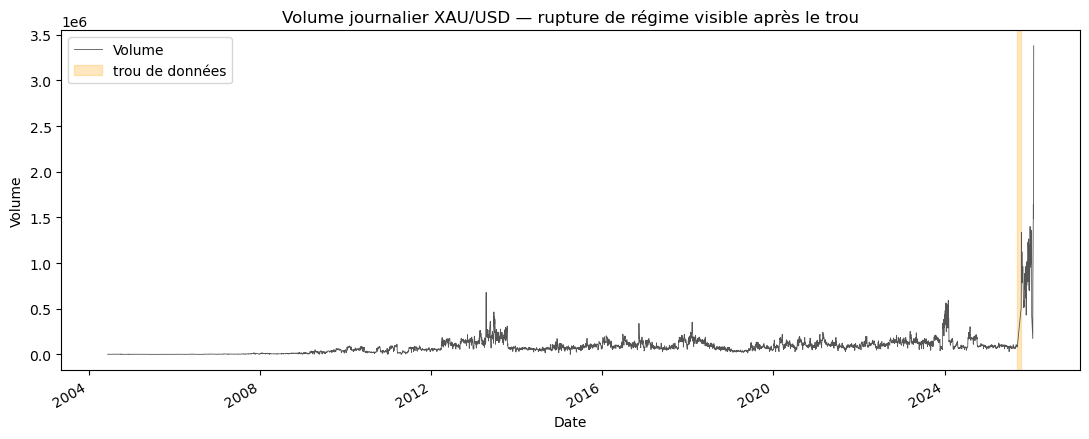

In [21]:
fig, ax = plt.subplots()
df["Volume"].plot(ax=ax, linewidth=0.6, color="#555")
ax.axvspan(pd.Timestamp("2025-09-12"), pd.Timestamp("2025-10-15"), color="orange", alpha=0.25, label="trou de données")
ax.set_title("Volume journalier XAU/USD — rupture de régime visible après le trou")
ax.set_ylabel("Volume")
ax.legend()
plt.tight_layout()
plt.show()

**Interprétation** — le volume moyen est multiplié par environ ×12 juste
après le trou. Ce n'est pas un choc de marché (les prix, eux, restent
cohérents d'un jour à l'autre une fois le trou passé) : c'est la signature
d'un changement de source/fournisseur de données concaténée dans ce
fichier. Conséquence pratique : **le volume n'est pas une variable fiable
sur l'ensemble de la série** — à exclure de toute feature engineering basée
sur le volume, sauf à le retraiter séparément avant/après la rupture.

## 5. Rendements logarithmiques

Le modèle (GBM / Monte Carlo / VaR) se calibre sur les rendements log, pas
sur les prix bruts (non stationnaires). `r_t = ln(Close_t / Close_{t-1})`.

**Point important** : le rendement calculé *à cheval sur un trou anormal*
n'est pas un rendement journalier — c'est un rendement cumulé sur toute la
période manquante, compressé dans une seule observation. Le garder tel
quel fausserait l'estimation de la volatilité journalière (une variation
de plusieurs semaines interprétée comme une variation d'un jour). On le
met à `NaN` plutôt que de le laisser polluer la série ou de supprimer la
ligne (qui reste valide pour les autres usages).

In [22]:
df["log_return"] = np.log(df["Close"] / df["Close"].shift(1))

# Neutraliser les rendements calculés à cheval sur un écart anormal (> 4 jours)
cross_gap_dates = abnormal_gaps.index
df.loc[cross_gap_dates, "log_return"] = np.nan

print(f"Rendements calculés : {df['log_return'].notna().sum()}")
print(f"Rendements neutralisés (cross-gap) : {len(cross_gap_dates)}")
df["log_return"].describe()

Rendements calculés : 5526
Rendements neutralisés (cross-gap) : 4


count    5526.000000
mean        0.000415
std         0.010906
min        -0.095045
25%        -0.004859
50%         0.000601
75%         0.006140
max         0.104267
Name: log_return, dtype: float64

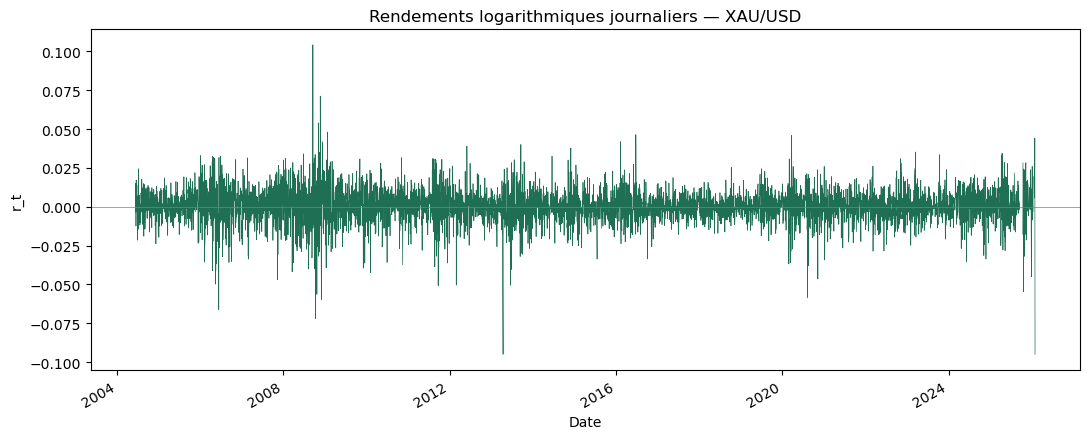

In [23]:
fig, ax = plt.subplots()
df["log_return"].plot(ax=ax, linewidth=0.5, color="#1f6f54")
ax.set_title("Rendements logarithmiques journaliers — XAU/USD")
ax.set_ylabel("r_t")
ax.axhline(0, color="grey", linewidth=0.5)
plt.tight_layout()
plt.show()

**Interprétation** — distribution centrée proche de 0, comme attendu pour
des rendements financiers. On voit déjà à l'œil des périodes de volatilité
nettement plus forte en fin de série (2025-2026), cohérent avec la hausse
accélérée de l'or sur cette période.

## 6. Détection des valeurs aberrantes (outliers statistiques)

Méthode z-score sur les rendements log (seuil |z| > 3, ~3 écarts-types).
**Un outlier statistique n'est pas automatiquement supprimé** : en gestion
du risque de marché, un mouvement extrême réel est justement ce que la VaR
et l'Expected Shortfall doivent capturer. L'objectif ici est de les
identifier et de documenter si c'est un vrai choc de marché ou une anomalie
de donnée suspecte — pas de nettoyer "à l'aveugle".

In [24]:
returns = df["log_return"].dropna()
z = (returns - returns.mean()) / returns.std()
outliers = df.loc[z[z.abs() > 3].index, ["Close", "log_return"]].copy()
outliers["z_score"] = z[z.abs() > 3]
outliers.sort_values("z_score", key=abs, ascending=False)

,Close,log_return,z_score
Date,,,
2008-09-17,863.50,0.104267,9.522577
2026-01-30,4889.48,-0.095045,-8.752992
2013-04-15,1348.00,-0.094993,-8.748272
2008-10-10,849.60,-0.071970,-6.637224
2008-11-21,800.00,0.071228,6.493044
...,...,...,...
2008-09-09,775.80,-0.032964,-3.060656
2008-10-07,888.00,0.033669,3.049144
2023-10-13,1932.41,0.033509,3.034499


**Interprétation** — chaque ligne ci-dessus est un jour où le rendement
dépasse 3 écarts-types de la moyenne historique. Avant de décider quoi en
faire pour la calibration du modèle : regarder si ces dates coïncident avec
des événements de marché connus (crise 2008, COVID 2020, le rallye de l'or
fin 2025 / début 2026 déjà repéré) — si oui, les garder dans la série
(c'est le signal que la VaR doit apprendre), et les isoler séparément
seulement pour la partie VaR stressée du module. Un outlier qui ne
coïncide avec aucun événement identifiable est le seul cas qui justifie
une vérification plus poussée de la donnée source.

## 7. Statistiques descriptives & volatilité

In [25]:
daily_vol = returns.std()
annualized_vol = daily_vol * np.sqrt(252)

print(f"Rendement moyen journalier : {returns.mean():.6f}")
print(f"Volatilité journalière     : {daily_vol:.6f}")
print(f"Volatilité annualisée      : {annualized_vol:.2%}")
print(f"Skewness                   : {returns.skew():.3f}")
print(f"Kurtosis (excès)           : {returns.kurt():.3f}")

Rendement moyen journalier : 0.000415
Volatilité journalière     : 0.010906
Volatilité annualisée      : 17.31%
Skewness                   : -0.429
Kurtosis (excès)           : 6.616


**Interprétation** — une kurtosis en excès nettement positive (attendue
ici) signale des queues de distribution plus épaisses qu'une loi normale :
c'est la raison pour laquelle la VaR paramétrique (qui suppose la
normalité) sous-estime typiquement le risque par rapport aux méthodes
historique ou Monte Carlo — point à garder pour la comparaison des 3
méthodes de VaR plus tard dans le pipeline.

## 8. Sauvegarde

In [26]:
import os
os.makedirs("../data/processed", exist_ok=True)
out = df[["Open", "High", "Low", "Close", "Volume", "log_return"]].copy()
out.to_csv("../data/processed/xau_1d_processed.csv")
print("Écrit :", "../data/processed/xau_1d_processed.csv", "—", len(out), "lignes")

Écrit : ../data/processed/xau_1d_processed.csv — 5531 lignes


## 9. Résumé & prochaine étape

- Fichier structurellement propre (0 NaN natif, 0 doublon, index trié).
- 1 trou anormal majeur (33j, sept-oct 2025) identifié, confirmé à toutes
  les granularités, avec rupture de régime de volume associée (×12) — le
  rendement log qui l'enjambe est neutralisé (`NaN`), pas supprimé.
- 2 écarts de 5j (2005, 2006) jugés normaux (fériés), 1 écart de 9j
  (jan. 2026) signalé mais non traité.
- Rendements log calculés, outliers statistiques identifiés et à
  documenter (pas supprimés par défaut).
- Volatilité annualisée calculée — sert de point de départ à la
  calibration GBM.

**Prochaine étape** : calibration du modèle GBM (dérive μ, volatilité σ) à
partir de cette série de rendements, puis moteur de simulation Monte
Carlo (`src/models/`).